# Assessments

In [1]:
# import relevant libraries to run the notebook
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

## 1. Exploring Petal length

In [2]:
# load the iris dataset 
iris = datasets.load_iris()


In [3]:
# read it as dataframe
iris_df = pd.DataFrame(iris.data, columns=iris.feature_names)
# preview df
iris_df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [4]:
# isolate petal length
iris_petal_length = iris_df['petal length (cm)']
iris_petal_length.head()

0    1.4
1    1.4
2    1.3
3    1.5
4    1.4
Name: petal length (cm), dtype: float64

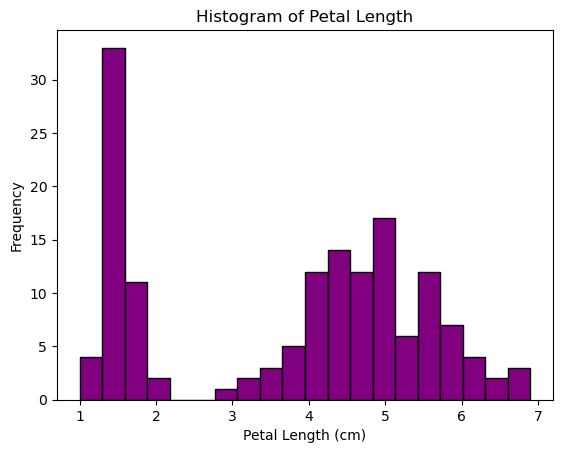

In [5]:
# plot data in a histogram 
plt.hist(iris_petal_length, bins=20, color='purple', edgecolor='black')
plt.xlabel('Petal Length (cm)')
plt.ylabel('Frequency')
plt.title('Histogram of Petal Length')
plt.show()

In [6]:
# calculate mean and standard deviation 
pl_mean = np.mean(iris_petal_length)
pl_std = np.std(iris_petal_length)
pl_mean, pl_std

(3.7580000000000005, 1.7594040657753032)

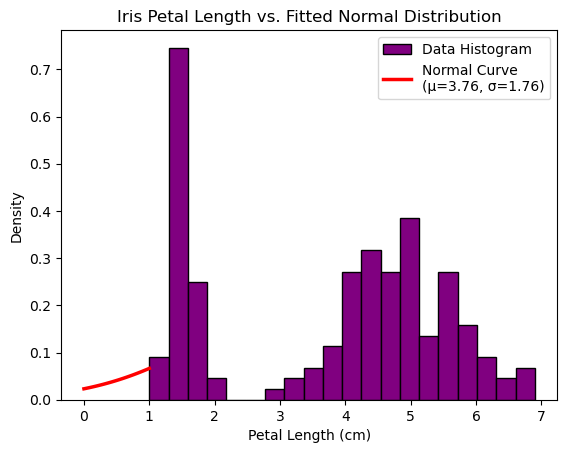

In [7]:
# Create an array of x-values spanning the dataset limits
xmin, xmax = plt.xlim()
x = np.linspace(xmin, xmax, 100)

# Compute the normal distribution curve values
p = stats.norm.pdf(x, pl_mean, pl_std)

# FIX: Added density=True so the scale matches the normal curve
plt.hist(iris_petal_length, bins=20, density=True, color='purple', edgecolor='black', label='Data Histogram')

# Superimpose the normal curve line
plt.plot(x, p, 'r-', linewidth=2.5, label=f'Normal Curve\n(μ={pl_mean:.2f}, σ={pl_std:.2f})')

# 7. Add layout metadata and labels
plt.title('Iris Petal Length vs. Fitted Normal Distribution')
plt.xlabel('Petal Length (cm)')
plt.ylabel('Density') # Y-axis represents relative likelihood, not counts
plt.legend()
plt.show()


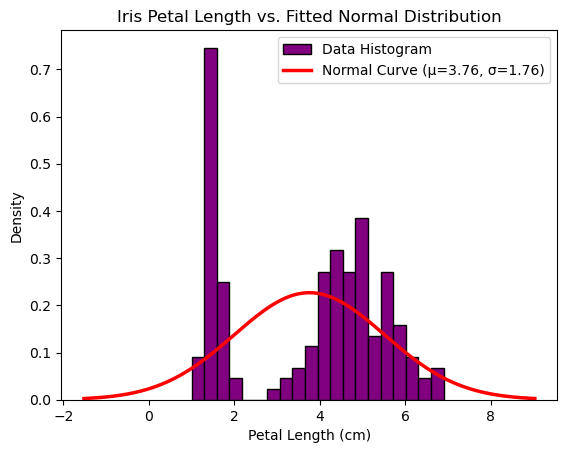

In [15]:
# Define x-axis range
# explain why we use 4 standard deviations from the mean
xmin = pl_mean - 3 * pl_std
xmax = pl_mean + 3 * pl_std

x = np.linspace(xmin, xmax, 200)

# Compute normal distribution curve
p = stats.norm.pdf(x, pl_mean, pl_std)

# Plot histogram
plt.hist(
    iris_petal_length,
    bins=20,
    density=True,
    color='purple',
    edgecolor='black',
    label='Data Histogram'
)

# Plot normal curve
plt.plot(
    x, p,
    'r-',
    linewidth=2.5,
    label=f'Normal Curve (μ={pl_mean:.2f}, σ={pl_std:.2f})'
)

plt.title('Iris Petal Length vs. Fitted Normal Distribution')
plt.xlabel('Petal Length (cm)')
plt.ylabel('Density')
plt.legend()
plt.show()


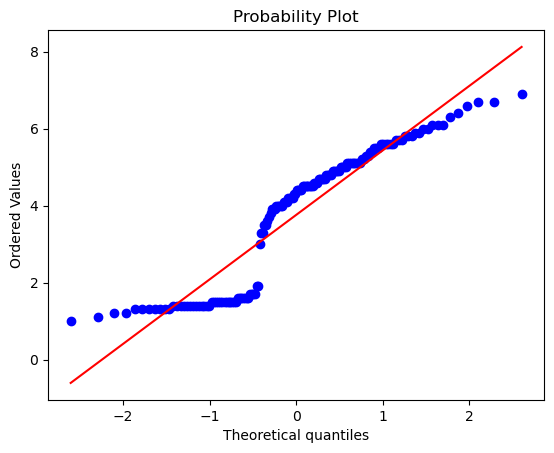

In [13]:
test1 = stats.probplot(iris_petal_length, dist="norm", plot=plt)

In [14]:
test2 = stats.shapiro(iris_petal_length)

test2

ShapiroResult(statistic=0.8762680554631075, pvalue=7.412263135173186e-10)

# End